## Aperture mask interpretation

The aperture mask contains integer bitmask values.

- Pixels with value `3` are included in the optimal aperture used to calculate the star's light curve.
- Pixels with value `1` belong to the downloaded target-pixel region but are not included in the optimal aperture.
- Pixels with value `0` are outside the valid aperture region.

The mask does not directly identify the physical size of the star. It identifies which detector pixels are selected for photometric measurement.

###### TIME — timestamp for each frame
###### FLUX_ERR — uncertainty/error on each flux measurement
###### FLUX_BKG — background flux (sky background, not the star)
###### QUALITY — flags for bad data points
###### COSMIC_RAYS — cosmic ray contamination per pixel

## Note
FITS arrays from NASA use big endian byte order (`>`).
PyTorch expects little endian. 
When building FITSDataset, call `.byteswap().newbyteorder()` 
on the numpy array before converting to tensor.

## Note
A single flux frame from HDU 1 has shape (8, 7) — matching the aperture mask.
Pixel values are in electrons/second (e-/s), ranging from ~30 to ~155,000.
This huge dynamic range requires percentile clipping before the image 
can be used as input to ResNet-50 or ViT.
This is fundamentally different from the aperture mask in HDU 2 
which only contains integer codes 0, 1, 3.

## Note
The flux frame visualization confirms:
- Star core sits around pixel (3,3) with ~155,000 e-/s brightness
- NaN pixels appear as white — these are dead/unused detector pixels
- The bright region aligns perfectly with the aperture mask's `3` valued pixels
- The dynamic range is extreme — background ~30, core ~155,000
- Simple normalization won't work — percentile clipping is essential
  before feeding into any neural network

## Note
3-channel conversion is done using `np.stack([img, img, img], axis=0)` 
giving shape (3, H, W).
Resizing from (3, 8, 7) to (3, 224, 224) will be handled by 
`torchvision.transforms.Resize(224)` inside FITSDataset in Phase 2.
This is a mandatory step before feeding into ResNet-50 or ViT.

In [40]:
tpf = lk.search_targetpixelfile(
    "Kepler-10",
    author="Kepler",
    quarter=1
).download()

with fits.open(tpf.path) as hdul:
    hdul.info()

    primary_header = hdul[0].header
    flux_hdu = hdul[1]
    aperture_hdu = hdul[2]

    print("Object:", primary_header["OBJECT"])
    print("RA:", primary_header["RA_OBJ"])
    print("DEC:", primary_header["DEC_OBJ"])

    aperture_mask = aperture_hdu.data

    print("Aperture shape:", aperture_mask.shape)
    print("Aperture dtype:", aperture_mask.dtype)
    print("Aperture min:", np.nanmin(aperture_mask))
    print("Aperture max:", np.nanmax(aperture_mask))

    all_flux_frames = flux_hdu.data["FLUX"]
    first_flux_frame = all_flux_frames[0]

print("All frames shape:", all_flux_frames.shape)
print("First frame shape:", first_flux_frame.shape)
print("Original dtype:", first_flux_frame.dtype)

first_flux_frame = np.asarray(first_flux_frame, dtype=np.float32)

fill_value = np.nanmedian(first_flux_frame)
clean_flux_frame = np.nan_to_num(
    first_flux_frame,
    nan=fill_value,
    posinf=fill_value,
    neginf=fill_value
)

low = np.percentile(clean_flux_frame, 1)
high = np.percentile(clean_flux_frame, 99)

clipped_flux_frame = np.clip(clean_flux_frame, low, high)

normalized_flux_frame = (
    clipped_flux_frame - clipped_flux_frame.min()
) / (
    clipped_flux_frame.max()
    - clipped_flux_frame.min()
    + 1e-8
)

flux_3ch = np.stack(
    [normalized_flux_frame] * 3,
    axis=0
).astype(np.float32)

print("Final shape:", flux_3ch.shape)
print("Final dtype:", flux_3ch.dtype)
print("Final range:", flux_3ch.min(), flux_3ch.max())

Filename: C:\Users\kriss\.cache\lightkurve\mastDownload\Kepler\kplr011904151_lc_Q111111110111011101\kplr011904151-2009166043257_lpd-targ.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      58   ()      
  1  TARGETTABLES    1 BinTableHDU    282   1639R x 13C   [D, E, J, 56J, 56E, 56E, 56E, 56E, 56E, J, E, E, 0E]   
  2  APERTURE      1 ImageHDU        48   (7, 8)   int32   
Object: KIC 11904151
RA: 285.679391
DEC: 50.2413
Aperture shape: (8, 7)
Aperture dtype: >i4
Aperture min: 0
Aperture max: 3
All frames shape: (1639, 8, 7)
First frame shape: (8, 7)
Original dtype: >f4
Final shape: (3, 8, 7)
Final dtype: float32
Final range: 0.0 1.0


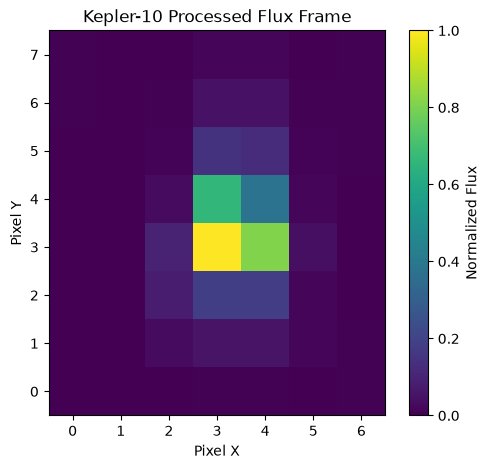

In [41]:
plt.figure(figsize=(6, 5))
plt.imshow(normalized_flux_frame, origin="lower", cmap="viridis")
plt.colorbar(label="Normalized Flux")
plt.title("Kepler-10 Processed Flux Frame")
plt.xlabel("Pixel X")
plt.ylabel("Pixel Y")
plt.show()

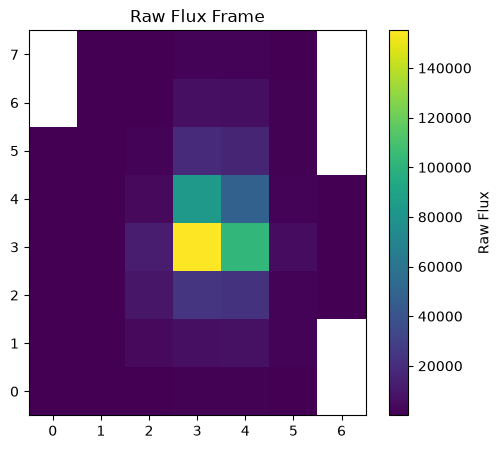

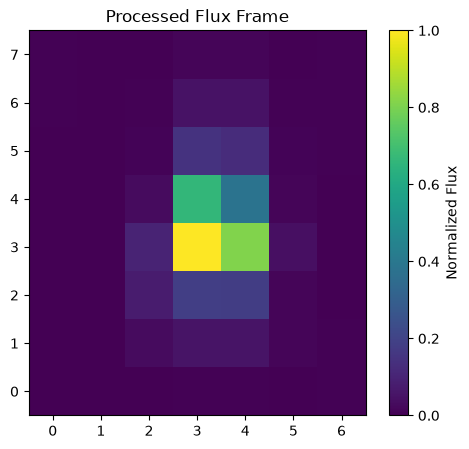

In [42]:
plt.figure(figsize=(6, 5))
plt.imshow(first_flux_frame, origin="lower", cmap="viridis")
plt.colorbar(label="Raw Flux")
plt.title("Raw Flux Frame")
plt.show()

plt.figure(figsize=(6, 5))
plt.imshow(normalized_flux_frame, origin="lower", cmap="viridis")
plt.colorbar(label="Normalized Flux")
plt.title("Processed Flux Frame")
plt.show()

## Observation

The raw flux frame contains a very large brightness range and may include NaN values.

The preprocessing steps were:

1. Convert the FITS big-endian array to native `float32`.
2. Replace NaN and infinite values.
3. Clip values between the 1st and 99th percentiles.
4. Normalize the remaining values into the range 0 to 1.
5. Duplicate the grayscale image into three channels.

The final array has shape `(3, 8, 7)` and can later be resized to `(3, 224, 224)` for ResNet-50 or ViT.

In [43]:
assert flux_3ch.shape == (3, 8, 7)
assert flux_3ch.dtype == np.float32
assert flux_3ch.min() >= 0
assert flux_3ch.max() <= 1

print("FITS preprocessing checks passed")

FITS preprocessing checks passed
